Import Libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

Load dataset

In [3]:
df = pd.read_csv("supermarket_data.csv")

Display Fisrt 5 Rows

In [4]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/10 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/10 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/10 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/10 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/10 08:26,3.39,17850.0,United Kingdom


Dataset Information

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      541910 non-null  str    
 1   StockCode    541910 non-null  str    
 2   Description  540456 non-null  str    
 3   Quantity     541910 non-null  int64  
 4   InvoiceDate  541910 non-null  str    
 5   Price        541910 non-null  float64
 6   Customer ID  406830 non-null  float64
 7   Country      541910 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


Check Missing values

In [6]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(5268)

Remove Duplicate Records

In [8]:
df.drop_duplicates(inplace=True)

In [9]:
df.duplicated().sum()

np.int64(0)

Date Conversion

In [11]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='mixed')

In [12]:
df['InvoiceDate'].dtype

dtype('<M8[us]')

Invalid Quantity check

In [13]:
df[df['Quantity'] <= 0].shape

(10587, 8)

Remove Invalid Quantity Records

In [14]:
df = df[df['Quantity'] > 0]

In [15]:
df[df['Quantity'] <= 0].shape

(0, 8)

Invalid price check

In [16]:
df[df['Price'] <= 0].shape

(1176, 8)

Remove Invalid Price Records

In [17]:
df = df[df['Price'] > 0]

In [18]:
df[df['Price'] <= 0].shape

(0, 8)

Revenue

In [19]:
df['Revenue'] = df['Quantity'] * df['Price']

In [20]:
df[['Quantity', 'Price', 'Revenue']].head()

,Quantity,Price,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


Data Cleaning

In [21]:
df.shape

(524879, 9)

Total Revenue

In [22]:
total_revenue = df['Revenue'].sum()
print(total_revenue)

10642128.804000001


Total Quantity Sold

In [23]:
total_quantity = df['Quantity'].sum()
print(total_quantity)

5572421


Total Orders

In [24]:
total_orders = df['Invoice'].nunique()
print(total_orders)

19960


Best Selling Product

In [25]:
best_selling_product = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False)

print(best_selling_product.head(1))

Description
PAPER CRAFT , LITTLE BIRDIE    80995
Name: Quantity, dtype: int64


Best Performing City

In [26]:
country_revenue = df.groupby('Country')['Revenue'].sum().sort_values(ascending=False)

print(country_revenue.head(1))

Country
United Kingdom    9001744.094
Name: Revenue, dtype: float64


Monthly Sales Analysis

In [27]:
df['Month'] = df['InvoiceDate'].dt.to_period('M')

In [28]:
monthly_sales = df.groupby('Month')['Revenue'].sum()

print(monthly_sales)

Month
2010-01      58776.790
2010-02      47629.420
2010-03      46898.630
2010-05      31364.630
2010-06      54624.150
2010-07      99553.850
2010-08      45235.360
2010-09      53548.190
2010-10      59021.020
2010-12     324800.690
2011-01     700510.610
2011-02     575211.670
2011-03     756961.460
2011-04     706669.411
2011-05     824906.880
2011-06     786516.590
2011-07     905018.561
2011-08     753503.840
2011-09    1203643.302
2011-10    1027029.940
2011-11    1336139.480
2011-12     244564.330
Freq: M, Name: Revenue, dtype: float64


Revenue by Country Bar Chart

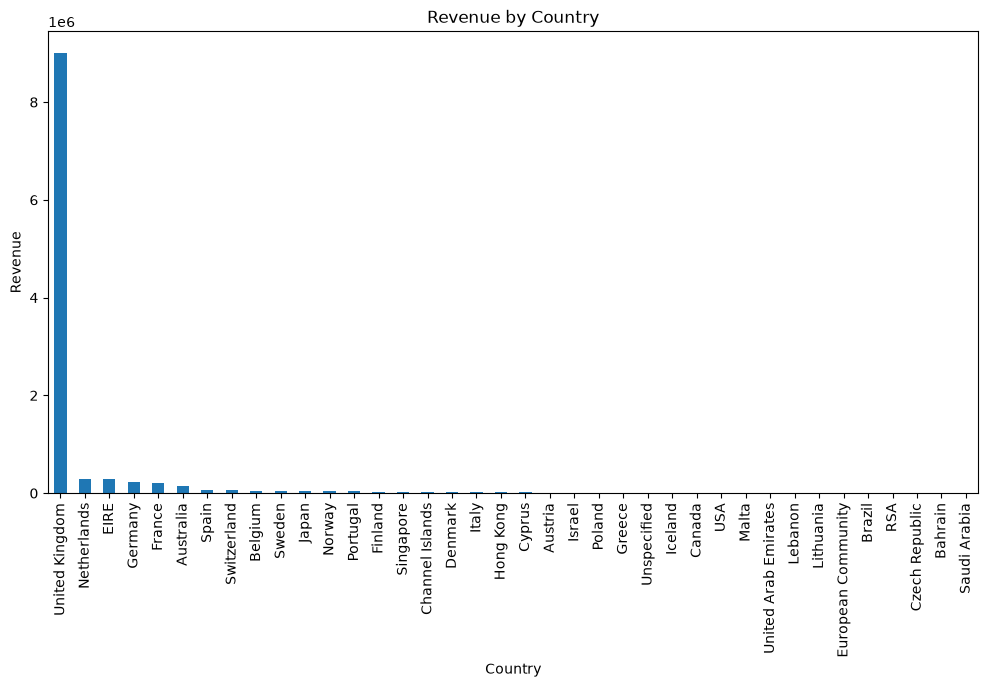

In [29]:
country_revenue = df.groupby('Country')['Revenue'].sum().sort_values(ascending=False)

country_revenue.plot(kind='bar', figsize=(12,6))

plt.title('Revenue by Country')
plt.xlabel('Country')
plt.ylabel('Revenue')
plt.xticks(rotation=90)
plt.show()

Category Contribution

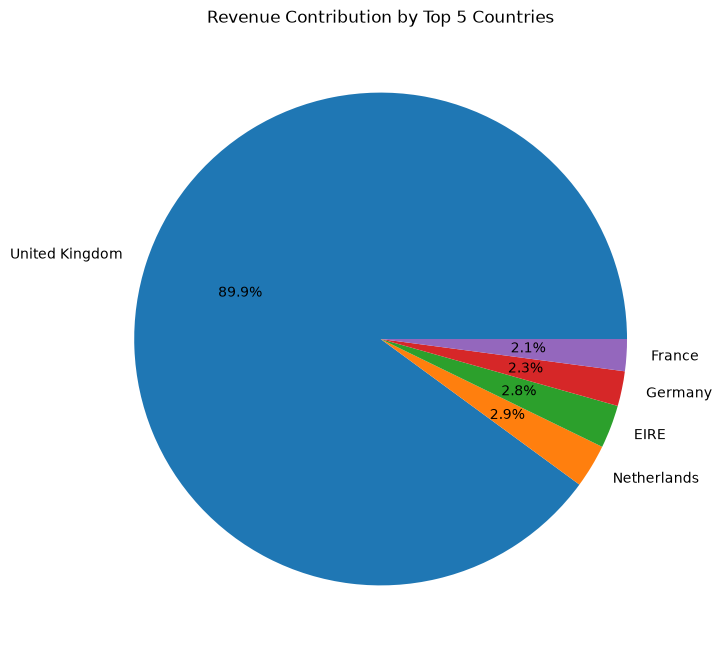

In [38]:
plt.figure(figsize=(8, 8))

values = country_revenue.head(5)

plt.pie(
    values.values,
    labels=values.index,
    autopct='%1.1f%%'
)

plt.title('Revenue Contribution by Top 5 Countries')

plt.savefig('country_contribution.png', dpi=300, bbox_inches='tight')

plt.show()

Monthly Sales Trend

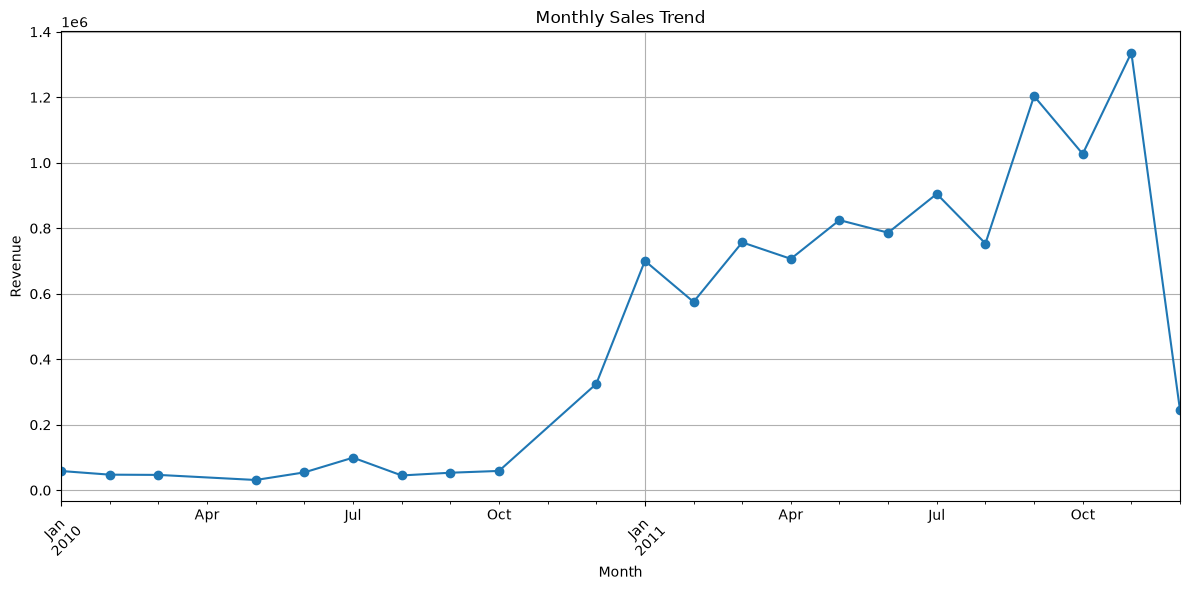

In [37]:
plt.figure(figsize=(12,6))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.savefig('monthly_sales_trend.png', dpi=300)
plt.show()

Business Insights


1. United Kingdom generated the highest revenue, with approximately 9.00 million in sales.
2. PAPER CRAFT, LITTLE BIRDIE was the best-selling product, with 80,995 units sold.
3. Total revenue generated was approximately 10.64 million, showing strong overall sales performance.
4. November 2011 recorded the highest monthly revenue, with approximately 1.34 million in sales.
5. Sales revenue increased significantly during 2011 compared with most months in 2010, indicating stronger sales activity in the later period.



Business Recommendations

1. Promote high-selling products 

Increase stock and marketing for products with high sales quantities, such as PAPER CRAFT, LITTLE BIRDIE.

2. Strengthen marketing in high-revenue markets

Focus more marketing and promotional campaigns on the United Kingdom, which generated the highest revenue.

3. Plan campaigns during low-sales months

Offer discounts, seasonal promotions, and special campaigns during lower-revenue months to improve sales performance.
